# PRAKTIKUM 4 — Visualisasi Data dengan Matplotlib (MATERI PENDAMPING)
**Mata kuliah:** Pengantar Machine Learning · **Minggu:** 4  
**Nama:** [Mochammad Maril Livio] · **NIM:** [231230065]

## 1. Membuat data sampel

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
hari = pd.date_range('2026-01-01', periods=30, freq='D')
data = pd.DataFrame({
    'tanggal': hari,
    'produk': rng.choice(['Kopi', 'Teh', 'Roti'], size=30),
    'jumlah': rng.integers(5, 35, size=30),
    'harga': rng.uniform(10000, 40000, size=30)
})
data['pendapatan'] = data['jumlah'] * data['harga']
print(data.head())

     tanggal produk  jumlah         harga     pendapatan
0 2026-01-01   Kopi      18  32342.864677  582171.564190
1 2026-01-02   Roti      11  39025.291973  429278.211703
2 2026-01-03    Teh       7  19774.760744  138423.325209
3 2026-01-04    Teh      21  21113.791181  443389.614802
4 2026-01-05    Teh      31  24086.674338  746686.904487


## 2. Line chart: pendapatan harian

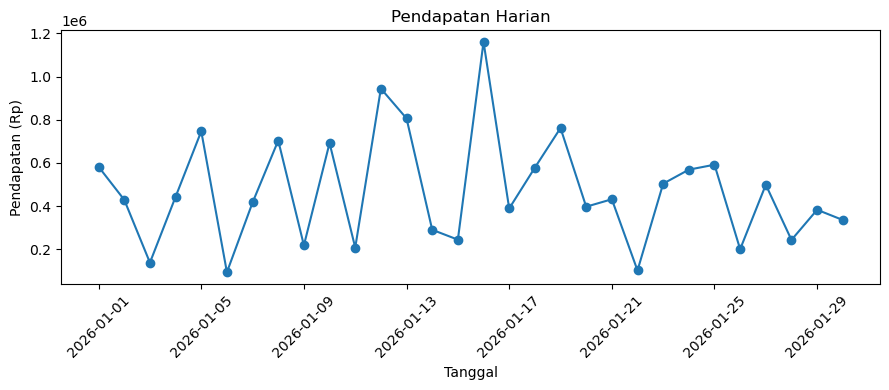

In [2]:
harian = data.groupby('tanggal')['pendapatan'].sum()
plt.figure(figsize=(9, 4))
plt.plot(harian.index, harian.values, marker='o')
plt.title('Pendapatan Harian')
plt.xlabel('Tanggal')
plt.ylabel('Pendapatan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Bar chart: total transaksi per produk

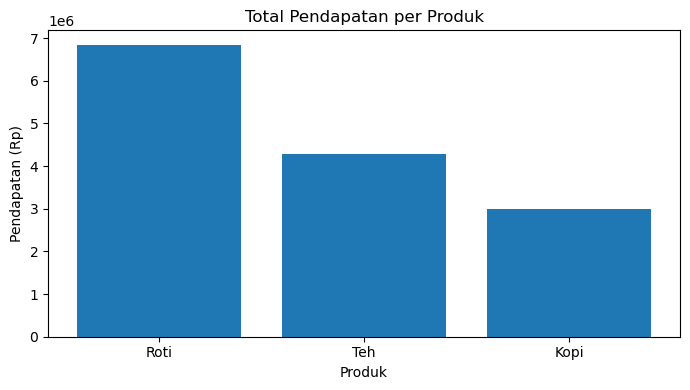

In [3]:
per_produk = data.groupby('produk')['pendapatan'].sum().sort_values(ascending=False)
plt.figure(figsize=(7,4))
plt.bar(per_produk.index, per_produk.values)
plt.title('Total Pendapatan per Produk')
plt.xlabel('Produk')
plt.ylabel('Pendapatan (Rp)')
plt.tight_layout()
plt.show()

## 4. Histogram dan scatter plot

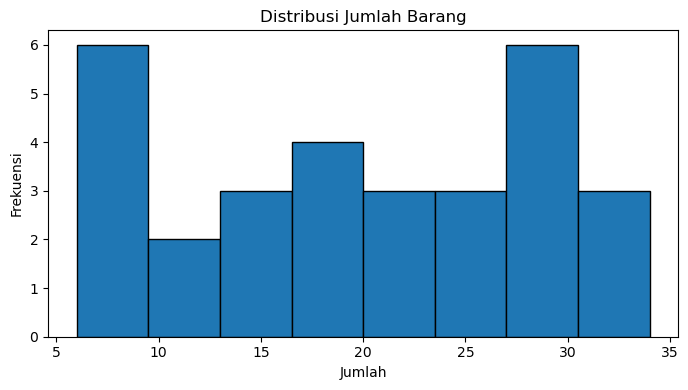

In [4]:
plt.figure(figsize=(7,4))
plt.hist(data['jumlah'], bins=8, edgecolor='black')
plt.title('Distribusi Jumlah Barang')
plt.xlabel('Jumlah')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

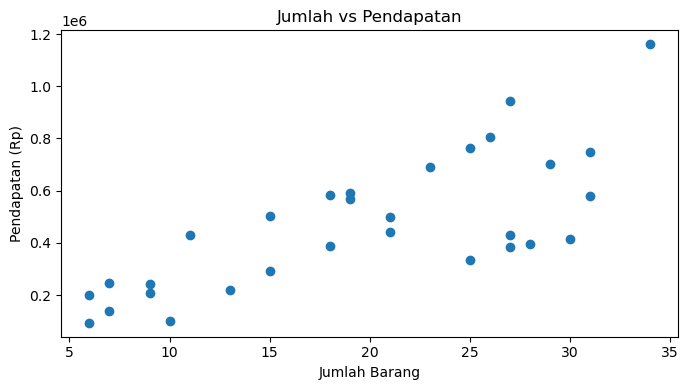

In [5]:
plt.figure(figsize=(7,4))
plt.scatter(data['jumlah'], data['pendapatan'])
plt.title('Jumlah vs Pendapatan')
plt.xlabel('Jumlah Barang')
plt.ylabel('Pendapatan (Rp)')
plt.tight_layout()
plt.show()

## 5. Latihan mandiri dan pengujian

In [6]:
rata_pendapatan = data['pendapatan'].mean()
median_pendapatan = data['pendapatan'].median()
produk_terlaris = data.groupby('produk')['jumlah'].sum().idxmax()

print(f'Rata-rata pendapatan: Rp{rata_pendapatan:,.2f}')
print(f'Median pendapatan: Rp{median_pendapatan:,.2f}')
print('Produk terlaris:', produk_terlaris)

assert len(data) == 30
assert (data['pendapatan'] > 0).all()
assert produk_terlaris in {'Kopi', 'Teh', 'Roti'}
print('✅ Contoh tambahan visualisasi berhasil dijalankan.')

Rata-rata pendapatan: Rp470,285.60
Median pendapatan: Rp430,601.93
Produk terlaris: Teh
✅ Contoh tambahan visualisasi berhasil dijalankan.
